**Problem 1: Dataset Description**

This dataset is a list of reviews from the fashion website rent the runway where users can rent formal wear and other items to use for special occasions. 

The dataset can be found here: https://cseweb.ucsd.edu/~jmcauley/datasets.html#clothing_fit

The following citation is adhered to for using the dataset Rishabh Misra, Mengting Wan, Julian McAuleyRecSys, 2018

In [1]:
import numpy
import urllib
import scipy.optimize
import random
from sklearn import svm 
from sklearn import linear_model
import ast
import gzip
import json

In [2]:
path = r'C:\Users\alexh\Python\Data Mining 256\Assignment 2\renttherunway_final_data.json'

In [3]:
f = open(path, "r", encoding="utf8") 

data = []

for l in f:
    d = json.loads(l)
    data.append(d)
f.close()

In [4]:
len(data)

192544

In [5]:
type(data)

list

In [6]:
data[0]

{'fit': 'fit',
 'user_id': '420272',
 'bust size': '34d',
 'item_id': '2260466',
 'weight': '137lbs',
 'rating': '10',
 'rented for': 'vacation',
 'review_text': "An adorable romper! Belt and zipper were a little hard to navigate in a full day of wear/bathroom use, but that's to be expected. Wish it had pockets, but other than that-- absolutely perfect! I got a million compliments.",
 'body type': 'hourglass',
 'review_summary': 'So many compliments!',
 'category': 'romper',
 'height': '5\' 8"',
 'size': 14,
 'age': '28',
 'review_date': 'April 20, 2016'}

This dataset consists of 192544 unique product reviews for each user. Every column in this dataset is an object data type 

This dataset consists of 14  different columns that are captured in a user's review of a product:
- fit (whether or not the product fits the user. Fit is equivalent to a yes, 
- user_id - this is the unique ID from each user who purchased a product from rent the runway
- bust_size - 
- item_id - the unique ID of the item being purchased 
- weight - the weight of the user in pounds 
- rating - the numerical rating that the user gave the product on a scale of 1-10
- rented for - the type of occasion that that user rented a product for  
- review_text - the written text that the user submitted when reviewing the item that they purchased 
- body type - the classification for the body type for each user
- review_summary - this is brief text that summarizes the content of the user's review 
- category - the different types of product lines that are used 
- height - how tall is the user in feet and inches
- size - the numeric value of each user's size
- age - how old is the user
- review_date - when did the user leave the review

In [7]:
#Data Cleaning

**The following data cleaning objectives were performed to ensure data quality**

1. Drop all null records and duplicate reocrds from the data
2. Convert the columns age and rating to integer values
3. Remove unnecessary string values from bust size and weight columns. Then, convert both of these columns to integer values
4. Split the height column into two seperate columns, feet and inches. Then removes strings from these values and returns them as integers. Then, create a new column to return the total number of inches 
5. Perform label encoding for the rented for columns
6. Remove size and age values with a value of 0

In [8]:
#2. Do basic data exploriation convert list into pandas  

In [9]:
#drop null values 

In [10]:
import pandas as pd

In [11]:
data2 = pd.DataFrame(data) 

In [12]:
data2

,fit,user_id,bust size,item_id,weight,rating,rented for,review_text,body type,review_summary,category,height,size,age,review_date
0,fit,420272,34d,2260466,137lbs,10,vacation,An adorable romper! Belt and zipper were a lit...,hourglass,So many compliments!,romper,"5' 8""",14,28,"April 20, 2016"
1,fit,273551,34b,153475,132lbs,10,other,I rented this dress for a photo shoot. The the...,straight & narrow,I felt so glamourous!!!,gown,"5' 6""",12,36,"June 18, 2013"
2,fit,360448,NaN,1063761,NaN,10,party,This hugged in all the right places! It was a ...,NaN,It was a great time to celebrate the (almost) ...,sheath,"5' 4""",4,116,"December 14, 2015"
3,fit,909926,34c,126335,135lbs,8,formal affair,I rented this for my company's black tie award...,pear,Dress arrived on time and in perfect condition.,dress,"5' 5""",8,34,"February 12, 2014"
4,fit,151944,34b,616682,145lbs,10,wedding,I have always been petite in my upper body and...,athletic,Was in love with this dress !!!,gown,"5' 9""",12,27,"September 26, 2016"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
192539,fit,66386,34dd,2252812,140lbs,10,work,Fit like a glove!,hourglass,LOVE IT!!! First Item Im thinking of buying!,jumpsuit,"5' 9""",8,42,"May 18, 2016"
192540,fit,118398,32c,682043,100lbs,10,work,The pattern contrast on this dress is really s...,petite,LOVE it!,dress,"5' 1""",4,29,"September 30, 2016"
192541,fit,47002,36a,683251,135lbs,6,everyday,"Like the other DVF wraps, the fit on this is f...",straight & narrow,"Loud patterning, flattering fit",dress,"5' 8""",8,31,"March 4, 2016"
192542,fit,961120,36c,126335,165lbs,10,wedding,This dress was PERFECTION. it looked incredib...,pear,loved this dress it was comfortable and photog...,dress,"5' 6""",16,31,"November 25, 2015"


In [13]:
data2.dtypes

fit               object
user_id           object
bust size         object
item_id           object
weight            object
rating            object
rented for        object
review_text       object
body type         object
review_summary    object
category          object
height            object
size               int64
age               object
review_date       object
dtype: object

In [14]:
data2 = data2.dropna()

In [15]:
len(data2)

146381

In [16]:
#check for duplicate values, there are 144 duplicate records

In [17]:
s = data2.duplicated()

In [18]:
s.value_counts()

False    146237
True        144
Name: count, dtype: int64

In [19]:
data2 = data2.drop_duplicates()

In [20]:
len(data2)

146237

In [21]:
data2

,fit,user_id,bust size,item_id,weight,rating,rented for,review_text,body type,review_summary,category,height,size,age,review_date
0,fit,420272,34d,2260466,137lbs,10,vacation,An adorable romper! Belt and zipper were a lit...,hourglass,So many compliments!,romper,"5' 8""",14,28,"April 20, 2016"
1,fit,273551,34b,153475,132lbs,10,other,I rented this dress for a photo shoot. The the...,straight & narrow,I felt so glamourous!!!,gown,"5' 6""",12,36,"June 18, 2013"
3,fit,909926,34c,126335,135lbs,8,formal affair,I rented this for my company's black tie award...,pear,Dress arrived on time and in perfect condition.,dress,"5' 5""",8,34,"February 12, 2014"
4,fit,151944,34b,616682,145lbs,10,wedding,I have always been petite in my upper body and...,athletic,Was in love with this dress !!!,gown,"5' 9""",12,27,"September 26, 2016"
5,fit,734848,32b,364092,138lbs,8,date,Didn't actually wear it. It fit perfectly. The...,athletic,Traditional with a touch a sass,dress,"5' 8""",8,45,"April 30, 2016"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
192539,fit,66386,34dd,2252812,140lbs,10,work,Fit like a glove!,hourglass,LOVE IT!!! First Item Im thinking of buying!,jumpsuit,"5' 9""",8,42,"May 18, 2016"
192540,fit,118398,32c,682043,100lbs,10,work,The pattern contrast on this dress is really s...,petite,LOVE it!,dress,"5' 1""",4,29,"September 30, 2016"
192541,fit,47002,36a,683251,135lbs,6,everyday,"Like the other DVF wraps, the fit on this is f...",straight & narrow,"Loud patterning, flattering fit",dress,"5' 8""",8,31,"March 4, 2016"
192542,fit,961120,36c,126335,165lbs,10,wedding,This dress was PERFECTION. it looked incredib...,pear,loved this dress it was comfortable and photog...,dress,"5' 6""",16,31,"November 25, 2015"


In [22]:
#convert age and rating columns to integer values 

In [23]:
data2['age'] = data2['age'].astype(int)

In [24]:
data2['rating'] = data2['rating'].astype(int)

In [25]:
#convert weight into an integer, remove string value, then convert to integer

In [26]:
data2["weight"] = data2["weight"].str[:-3]

In [27]:
data2['weight'] = data2['weight'].astype(int)

In [28]:
#convert bust size into an integer, remove string value, then convert into integer 

In [29]:
data2["bust size"] = data2["bust size"].str[:2]

In [30]:
data2['bust size'] = data2['bust size'].astype(int)

In [31]:
#split height into feet and inches, then create a column that is "total inches"

In [32]:
data2[['Feet', 'Inches']] = data2['height'].str.split(' ', expand=True)

In [33]:
data2["Feet"] = data2["Feet"].str[:-1]

In [34]:
data2['Feet'] = data2['Feet'].astype(int)

In [35]:
data2["Inches"] = data2["Inches"].str[:-1]

In [36]:
data2['Inches'] = data2['Inches'].astype(int)

In [37]:
data2["tot_inches"] = data2["Feet"]*12 + data2["Inches"]

In [38]:
data2

,fit,user_id,bust size,item_id,weight,rating,rented for,review_text,body type,review_summary,category,height,size,age,review_date,Feet,Inches,tot_inches
0,fit,420272,34,2260466,137,10,vacation,An adorable romper! Belt and zipper were a lit...,hourglass,So many compliments!,romper,"5' 8""",14,28,"April 20, 2016",5,8,68
1,fit,273551,34,153475,132,10,other,I rented this dress for a photo shoot. The the...,straight & narrow,I felt so glamourous!!!,gown,"5' 6""",12,36,"June 18, 2013",5,6,66
3,fit,909926,34,126335,135,8,formal affair,I rented this for my company's black tie award...,pear,Dress arrived on time and in perfect condition.,dress,"5' 5""",8,34,"February 12, 2014",5,5,65
4,fit,151944,34,616682,145,10,wedding,I have always been petite in my upper body and...,athletic,Was in love with this dress !!!,gown,"5' 9""",12,27,"September 26, 2016",5,9,69
5,fit,734848,32,364092,138,8,date,Didn't actually wear it. It fit perfectly. The...,athletic,Traditional with a touch a sass,dress,"5' 8""",8,45,"April 30, 2016",5,8,68
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
192539,fit,66386,34,2252812,140,10,work,Fit like a glove!,hourglass,LOVE IT!!! First Item Im thinking of buying!,jumpsuit,"5' 9""",8,42,"May 18, 2016",5,9,69
192540,fit,118398,32,682043,100,10,work,The pattern contrast on this dress is really s...,petite,LOVE it!,dress,"5' 1""",4,29,"September 30, 2016",5,1,61
192541,fit,47002,36,683251,135,6,everyday,"Like the other DVF wraps, the fit on this is f...",straight & narrow,"Loud patterning, flattering fit",dress,"5' 8""",8,31,"March 4, 2016",5,8,68
192542,fit,961120,36,126335,165,10,wedding,This dress was PERFECTION. it looked incredib...,pear,loved this dress it was comfortable and photog...,dress,"5' 6""",16,31,"November 25, 2015",5,6,66


In [39]:
#build a specific label encoder for the fit column 

In [40]:
encoding_map = {"small": 0, "fit": 1, "large": 2}

In [41]:
data2['encoded fit'] = data2['fit'].map(encoding_map)

In [42]:
#remove records from the dataset where age and size are 0

In [43]:
data2.drop(data2[data2["age"] == 0].index, inplace=True)

In [44]:
len(data2)

146216

In [45]:
#remove records from dataset where size is 0

In [46]:
data2.drop(data2[data2["size"] == 0].index, inplace=True)

In [47]:
len(data2)

145779

**Observations from Data Explorations**

- the ratings provided by the customers are overwhemlingly skewed, very rarely does a user provide a bad review. The average rating for a user is a little over 9 out of 10
- The most popular occasion for doing business with rent the runway is acquiring an outfit for a wedding. 29.1% of rentals were for weddings 
- Roughly 73.5% of consumers indicated that their outfit "fit"
- The top ten most popular product lines are: dresses, gowns, sheaths, shifts, jumpsuit, top, maxis, rompers, jackets and minis
- the distribution for the age and size columns are skewed to the right, might need to be transformed later on       

In [48]:
data2

,fit,user_id,bust size,item_id,weight,rating,rented for,review_text,body type,review_summary,category,height,size,age,review_date,Feet,Inches,tot_inches,encoded fit
0,fit,420272,34,2260466,137,10,vacation,An adorable romper! Belt and zipper were a lit...,hourglass,So many compliments!,romper,"5' 8""",14,28,"April 20, 2016",5,8,68,1
1,fit,273551,34,153475,132,10,other,I rented this dress for a photo shoot. The the...,straight & narrow,I felt so glamourous!!!,gown,"5' 6""",12,36,"June 18, 2013",5,6,66,1
3,fit,909926,34,126335,135,8,formal affair,I rented this for my company's black tie award...,pear,Dress arrived on time and in perfect condition.,dress,"5' 5""",8,34,"February 12, 2014",5,5,65,1
4,fit,151944,34,616682,145,10,wedding,I have always been petite in my upper body and...,athletic,Was in love with this dress !!!,gown,"5' 9""",12,27,"September 26, 2016",5,9,69,1
5,fit,734848,32,364092,138,8,date,Didn't actually wear it. It fit perfectly. The...,athletic,Traditional with a touch a sass,dress,"5' 8""",8,45,"April 30, 2016",5,8,68,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
192539,fit,66386,34,2252812,140,10,work,Fit like a glove!,hourglass,LOVE IT!!! First Item Im thinking of buying!,jumpsuit,"5' 9""",8,42,"May 18, 2016",5,9,69,1
192540,fit,118398,32,682043,100,10,work,The pattern contrast on this dress is really s...,petite,LOVE it!,dress,"5' 1""",4,29,"September 30, 2016",5,1,61,1
192541,fit,47002,36,683251,135,6,everyday,"Like the other DVF wraps, the fit on this is f...",straight & narrow,"Loud patterning, flattering fit",dress,"5' 8""",8,31,"March 4, 2016",5,8,68,1
192542,fit,961120,36,126335,165,10,wedding,This dress was PERFECTION. it looked incredib...,pear,loved this dress it was comfortable and photog...,dress,"5' 6""",16,31,"November 25, 2015",5,6,66,1


In [49]:
data2.pivot_table(index="fit", values=["size", "age", "rating", "tot_inches"], aggfunc="mean").sort_values(by=["size"], ascending=True).head(10).round(1)

,age,rating,size,tot_inches
fit,,,,
large,33.8,8.5,10.0,65.2
fit,34.1,9.3,11.3,65.3
small,34.3,8.4,13.7,65.3


In [50]:
data2.pivot_table(index="rented for", values=["size", "age", "rating", "tot_inches"], aggfunc="mean").sort_values(by=["size"], ascending=True).head(10).round(1)

,age,rating,size,tot_inches
rented for,,,,
everyday,35.7,8.8,10.7,65.4
date,34.8,8.9,11.0,65.2
other,34.1,9.1,11.1,65.1
work,35.8,8.8,11.1,65.3
vacation,35.2,9.0,11.3,65.3
wedding,32.8,9.2,11.6,65.2
party,34.6,9.0,11.6,65.3
formal affair,33.9,9.2,11.9,65.4
party: cocktail,35.0,8.0,12.0,62.0


In [51]:
import pandas as pd
import seaborn as sns

In [52]:
data2["age"].describe()

count    145779.000000
mean         34.102738
std           8.102173
min           1.000000
25%          29.000000
50%          32.000000
75%          37.000000
max         117.000000
Name: age, dtype: float64

In [53]:
data2["size"].describe()

count    145779.000000
mean         11.472743
std           7.814681
min           1.000000
25%           4.000000
50%           9.000000
75%          16.000000
max          58.000000
Name: size, dtype: float64

In [54]:
data2["rating"].describe()

count    145779.000000
mean          9.081226
std           1.438332
min           2.000000
25%           8.000000
50%          10.000000
75%          10.000000
max          10.000000
Name: rating, dtype: float64

In [55]:
data2["weight"].describe()

count    145779.000000
mean        137.295228
std          21.515137
min          50.000000
25%         124.000000
50%         135.000000
75%         148.000000
max         300.000000
Name: weight, dtype: float64

In [56]:
data2["bust size"].describe()

count    145779.000000
mean         34.115366
std           1.701560
min          28.000000
25%          32.000000
50%          34.000000
75%          36.000000
max          48.000000
Name: bust size, dtype: float64

In [57]:
import matplotlib.pyplot as plt

In [58]:
plt.hist(data=data2, x="age", bins=15, edgecolor="black")
plt.title("Distirbution for Age in Dataset")
plt.xlabel("Customer's Age")
plt.ylabel("Numerical Count")
plt.
plt.grid()
plt.show()

SyntaxError: invalid syntax (2074653550.py, line 5)

In [ ]:
plt.hist(data=data2, x="size", bins=15, edgecolor="black")
plt.title("Distribution of customer sizes")
plt.xlabel("size")
plt.ylabel("Numerical Count")
plt.grid()
plt.show()

In [ ]:
plt.hist(data=data2, x="rating", edgecolor="black")
plt.title("Distribution of Rating by Customer")
plt.xlabel("Distirbution of Rating By Customer")
plt.ylabel("Numerical Count")
plt.show()

In [ ]:
plt.hist(data=data2, x="weight", bins=15, edgecolor="black")
plt.title("Distribution of weight")
plt.xlabel("weight")
plt.ylabel("Numerical Count")
plt.grid()
plt.show()

In [ ]:
data2["age"].mean().round(1)

In [ ]:
data2["size"].mean().round(1)

In [ ]:
data2["weight"].mean().round(1)

In [ ]:
#compositino of special occasions

In [ ]:
plt.figure(figsize=(15, 10))
sns.countplot(data=data2, x='rented for', hue="rented for", order=data2['rented for'].value_counts().index)
plt.title("Composition of Special Occasions for Respective Customers")
plt.show()

In [ ]:
data2['rented for'].value_counts()

In [ ]:
wedding = (42406)/145779
print(wedding)

In [ ]:
#count of ratings

In [ ]:
plt.figure(figsize=(15, 10))
sns.countplot(data=data2, x='rating', hue="rating", order=data2['rating'].value_counts().index)
plt.title("Composition of Ratings for Customers")
plt.show()

In [ ]:
data2['rating'].value_counts().head(10)

In [ ]:
perfect = (93869)/145779
print(perfect)

In [ ]:
positive = (93867+40613)/145779
print(positive)

In [ ]:
data2['category'].value_counts().head(10)

In [ ]:
plt.figure(figsize=(15, 10))
sns.countplot(data=data2, x='fit', hue="fit", order=data2['fit'].value_counts().index)
plt.title("Composition of Fit Respective Customers")
plt.show()

In [ ]:
data2['fit'].value_counts()

In [ ]:
productfit = 107239/145779
print(productfit)

In [ ]:
len(data2)

In [ ]:
#convert Dataframe back into a dictionary

In [64]:
dict_list = data2.to_dict('records')

In [65]:
dict_list[0]

{'fit': 'fit',
 'user_id': '420272',
 'bust size': 34,
 'item_id': '2260466',
 'weight': 137,
 'rating': 10,
 'rented for': 'vacation',
 'review_text': "An adorable romper! Belt and zipper were a little hard to navigate in a full day of wear/bathroom use, but that's to be expected. Wish it had pockets, but other than that-- absolutely perfect! I got a million compliments.",
 'body type': 'hourglass',
 'review_summary': 'So many compliments!',
 'category': 'romper',
 'height': '5\' 8"',
 'size': 14,
 'age': 28,
 'review_date': 'April 20, 2016',
 'Feet': 5,
 'Inches': 8,
 'tot_inches': 68,
 'encoded fit': 1}

In [66]:
len(dict_list)

145779

**Question 2**

My class is to develop a multi class logistic classification model to predict the y value of "fit"; the class weight will need to be balanced to perform this scenario 
- review text column
-  bust size
-  weight
-  age
-  size
- total_inches

I decided to build a logistic classification model to assess the accuracy as a baseline. The model's accuracy can be assessed by the accuracy of correct predictions divided by the length of correct predictions. 

I split the dataset into training, validation, and testing splits to prevent overfitting. In total, the dataframe has 145779 records. The training set contains the first 116623 records in the data frame. The validation data set is 14578 records and the test data set is 14578 records. This train test validation split consists of 80% training, 10% validation and 10% test 

All of these models will be implemented with the class_weight balanced feature in the logistic regression model as the majority of customers have indicated that their outfit "fit"

After finding the classification model that returns the highest accuracy, I will attempt to optimize the performance of that model by trying the following steps 

- adjust train test validation split (I adjusted the train test valid split ratio from 80%, 10%, 10% to 70%, 15%, 15% )
- perform standard scaling on the x features prior to training the model
- remove outliers for age and size columns, then perform the logistic regression model
- removed feature age from the x values 
- perform log transformation on size column
- building a regularization pipeline to optimize the accuracy for the model that performs the best
- Does the best model perform better on a multi classification problem as compared to a binary classification? 

1.Logistic Classification Accuracy Score for baseline model: 51.95%
<p>2.Logistic Classification Accuracy Score with adjusted train test split: 52.15%<p>
<p>3.Logistic Classification Accuracy Score after standard scaling of x values 52.49%<p>
<p>4.Logistic Classification Accuracy Score after removing outliers for age and size and performing train test split adjustment 51.60% <p>
<p>5.Logistic Classification Accuracy Score after removing the feature of age and including the train test split 52.56%<p>
<p>6.Logistic Classification Accuracy Score after performing a natural log adjustment on the size column and standard scaling of x values 51.11%<p>


<p>7. Return the best values for the logistic classification Accuracy Score using model adjustment number 5 (adjusted train test split and age is removed)
    <p>- The accuracy for this model when it is fully optimized is 52.60%<p>
    - The best returns the following information
C = 0.0001; Testing BER = 0.4739231061452205, Testing Accuracy Score = 0.5260768938547795<p>

<p> 8. Logistic Classification Accuracy Score on multi label classification for the y variable of (fit) 44.64%<p>

The following conclusions were generated from this part 
1. The logistic classifier's performance with the respective x values predicting the y value performs slighly better as compared to randomly guessing. However, this logistic classifier is very weak and should not be considered as a good indicator of predicting whether the users outfit actually fits
2. The adjustments to the baseline model that actually perform better than the baseline model are the following
  - adjusting the train test valid split from 0.80, 0.10, 0.10 to 0.70, 0.15, 0.15
  - Performing a logistic regression model with a train test split of  0.70, 0.15, 0.15 and performing a standard scaler transform on the x values prior to training the model
  - Performing a logistic regression model with a train test split of  0.70, 0.15, 0.15 and removing the age of the x features
3. The best-performing model had the x features of bust_size, weight, size and total inches along with the y value of fit.
4. Even though the accuracy for the binary classification model is slightly better than randomly guessing, performing a multi classification model on the encoded variable performs worse than randomly guessing. 


## Problem 2 Part 1: 
Perform a logistic classification model on the following x features with the intention of predicting whether the product purchased fits 
The baseline model return with an acuracy score of 51.95%, clearly more work needs to be done to optimize it's performance 

In [67]:
#use balanced accuracy score, the y value is imbalanced 

In [68]:
from sklearn.metrics import balanced_accuracy_score

In [69]:
def feature(datum):
    a = datum["bust size"]
    b = datum["weight"]
    c = datum["age"]
    d = datum["size"]
    e = datum["tot_inches"]
    return [1, a, b, c, d, e]

In [70]:
X = [feature(d) for d in dict_list]

In [71]:
y = [d["fit"] == "fit" for d in dict_list]

In [72]:
len(dict_list)

145779

In [73]:
Ntrain = 116623
NValid = 14578
Ntest = 14578

In [74]:
dataTrain = dict_list[:Ntrain]
dataValid = dict_list[Ntrain:Ntrain+NValid]
dataTest = dict_list[NValid:NValid + Ntest]

In [75]:
Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [76]:
from sklearn.linear_model import LogisticRegression

In [77]:
mod = linear_model.LogisticRegression(class_weight="balanced")
mod.fit(Xtrain, ytrain)

LogisticRegression(class_weight='balanced')

In [78]:
predictions = mod.predict(Xtest)

In [79]:
accuracy = balanced_accuracy_score(ytest, predictions)

In [80]:
accuracy

0.5195530179179751

Question 2 Part 2: Does the performance of the logistic classification model improve by adjusting the train valid test split ratio? 

I adjusted the train test valid split ratio from 80%, 10%, 10% to 70%, 15%, 15%  

the adjustments in the train test split did improve the accuracy as compared to the baseline model. The accuracy score is now 52.51%

In [81]:
len(dict_list)

145779

In [82]:
Ntrain = 102045
NValid = 21867
Ntest = 21867

In [83]:
Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [84]:
def feature(datum):
    a = datum["bust size"]
    b = datum["weight"]
    c = datum["age"]
    d = datum["size"]
    e = datum["tot_inches"]
    return [1, a, b, c, d, e]

In [85]:
X = [feature(d) for d in dict_list]

In [86]:
y = [d["fit"] == "fit" for d in dict_list]

In [87]:
from sklearn.linear_model import LogisticRegression

In [88]:
mod = linear_model.LogisticRegression(class_weight="balanced")
mod.fit(Xtrain, ytrain)

LogisticRegression(class_weight='balanced')

In [89]:
predictions = mod.predict(Xtest)

In [90]:
classaccuracy1 = balanced_accuracy_score(ytest, predictions)

In [91]:
classaccuracy1

0.5251576938669427

Question 2 Part 3: Does this model perform better as the result of implementing a standard scaler in addition to the adjusted train test split?

The accuracy of the logistic classification model increased to 52.49% percent. <p>The standard scaling of the x values performs better than the baseline model, but it does not perform better than the model that only contained the adjustment to the train test split 

In [102]:
#use the same train test split as the second part 

In [92]:
Ntrain = 102045
NValid = 21867
Ntest = 21867

In [93]:
Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [94]:
def feature(datum):
    a = datum["bust size"]
    b = datum["weight"]
    c = datum["age"]
    d = datum["size"]
    e = datum["tot_inches"]
    return [1, a, b, c, d, e]

In [95]:
X = [feature(d) for d in dict_list]
y = [d["fit"] == "fit" for d in dict_list]

In [96]:
from sklearn.preprocessing import StandardScaler

In [97]:
sc = StandardScaler()
Xtrain = sc.fit_transform(Xtrain)
Xtest = sc.transform(Xtest)

In [98]:
from sklearn.linear_model import LogisticRegression
mod = linear_model.LogisticRegression(class_weight="balanced")
mod.fit(Xtrain, ytrain)

LogisticRegression(class_weight='balanced')

In [99]:
predictions = mod.predict(Xtest)

In [100]:
classaccuracy2 = balanced_accuracy_score(ytest, predictions)

In [101]:
classaccuracy2

0.5249031222147006

Question 2: Part 4 Run this model in question 2 part 2 again after removing outliers for the age column

I also performed the train test split adjustment of adjusting the train test valid split ratio from 80%, 10%, 10% to 70%, 15%, 15%  

After removing the outliers and creating a dictionary with the outliers, I learned that the accuracy of the model returns as 51.60%. This model performs worse than the baseline model and every other model that has been deployed

Removing the outliers from the age and size x features actually decreased the accuracy score as compared to every other model that has been deployed

In [113]:
#define outliers for age column

In [106]:
import numpy as np

In [107]:
data3 = data2

In [108]:
Q1 = data3['age'].quantile(0.25)
Q3 = data3['age'].quantile(0.75)

In [109]:
IQR = Q3 - Q1

In [110]:
threshold = 1.5

In [111]:
outliers = data3[(data3['age'] < Q1 - threshold * IQR) | (data3['age'] > Q3 + threshold * IQR)]

In [112]:
data3 = data3.drop(outliers.index)

In [113]:
len(data3)

137600

In [114]:
Q1 = data3['size'].quantile(0.25)
Q3 = data3['size'].quantile(0.75)

In [115]:
IQR = Q3 - Q1

In [116]:
threshold = 1.5

In [117]:
outliers = data3[(data3['size'] < Q1 - threshold * IQR) | (data3['size'] > Q3 + threshold * IQR)]

In [118]:
data3 = data3.drop(outliers.index)

In [119]:
len(data3)

135663

In [120]:
#convert the new dataframe to a list 

In [121]:
dict_list3 = data3.to_dict('records')

In [122]:
len(dict_list3)

135663

In [123]:
#now that the outliers are removed, define the train valid test split (train 80%, valid 10% and test 10%)

In [124]:
Ntrain = 108530
NValid = 13566
Ntest = 13566

In [125]:
#now run the classification model 

In [126]:
def feature(datum):
    a = datum["bust size"]
    b = datum["weight"]
    c = datum["age"]
    d = datum["size"]
    e = datum["tot_inches"]
    return [1, a, b, c, d, e]

In [127]:
X = [feature(d) for d in dict_list3]
y = [d["fit"] == "fit" for d in dict_list3]

In [128]:
Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [129]:
sc = StandardScaler()
Xtrain = sc.fit_transform(Xtrain)
Xtest = sc.transform(Xtest)

In [130]:
from sklearn.linear_model import LogisticRegression
mod = linear_model.LogisticRegression(class_weight="balanced")
mod.fit(Xtrain, ytrain)
predictions = mod.predict(Xtest)

In [131]:
classaccuracy3 = balanced_accuracy_score(ytest, predictions)

In [132]:
classaccuracy3

0.516093281313482

Question 2 Part 5: remove a value from the x features, I decided to remove age as I do not believe that there age is a strong predictor of determining whether the outfit actually fits.
The accuracy score of the model is 52.56%. 
This model performs the best out of all the models that were previously deployed 

In [133]:
len(dict_list)

145779

In [134]:
#use the same train test split 

In [135]:
len(dict_list)

145779

In [136]:
Ntrain = 102045
NValid = 21867
Ntest = 21867

In [137]:
def feature(datum):
    a = datum["bust size"]
    b = datum["weight"]
    c = datum["size"]
    d = datum["tot_inches"]
    return [1, a, b, c, d]

In [138]:
X = [feature(d) for d in dict_list]
y = [d["fit"] == "fit" for d in dict_list]

In [139]:
Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [140]:
sc = StandardScaler()
Xtrain = sc.fit_transform(Xtrain)
Xtest = sc.transform(Xtest)

In [141]:
from sklearn.linear_model import LogisticRegression
mod = linear_model.LogisticRegression(class_weight="balanced")
mod.fit(Xtrain, ytrain)

LogisticRegression(class_weight='balanced')

In [142]:
predictions = mod.predict(Xtest)

In [143]:
classaccuracy4= balanced_accuracy_score(ytest, predictions)

In [144]:
classaccuracy4

0.5255637741141878

Question 2 Part 6: <p>perform a log transformation on the size column, then perform the logistic classification model without the age in the x features
<p>. <p>I performed a natural log adjustment on the size column with the intention of trying to generate a logistic regression model where that column is shaped more like a uniform distirbution.<p> <p>However, the accuracy score is the 51.11%, which is the worst performing model out of all of them

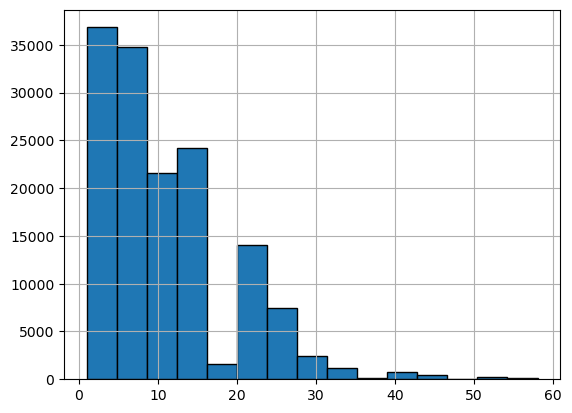

In [1098]:
plt.hist(data2["size"], bins=15, edgecolor="black")
plt.grid()
plt.show()

In [1099]:
data2["size_natural_log"] = np.log(data2["size"])

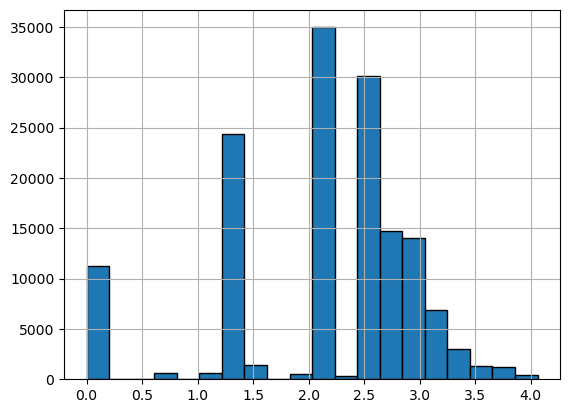

In [1100]:
plt.hist(data2["size_natural_log"], bins=20, edgecolor="black")
plt.grid()
plt.show()

In [1101]:
dict_list = data2.to_dict('records')

In [1102]:
Ntrain = 102045
NValid = 21867
Ntest = 21867

In [1103]:
def feature(datum):
    a = datum["bust size"]
    b = datum["weight"]
    c = datum["size_natural_log"]
    d = datum["tot_inches"]
    return [1, a, b, c, d]

In [1105]:
X = [feature(d) for d in dict_list]
y = [d["fit"] == "fit" for d in dict_list]

In [1106]:
Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [ ]:
sc = StandardScaler()
Xtrain = sc.fit_transform(Xtrain)
Xtest = sc.transform(Xtest)

In [1107]:
from sklearn.linear_model import LogisticRegression
mod = linear_model.LogisticRegression(class_weight="balanced")
mod.fit(Xtrain, ytrain)

LogisticRegression(class_weight='balanced')

In [1108]:
predictions = mod.predict(Xtest)

In [1109]:
classaccuracy5= balanced_accuracy_score(ytest, predictions)

In [1110]:
classaccuracy5

0.5111802019838163

Question 2 Part 7: Perform a regularization model on the model that performed the best (Question 2 part 5, train test split and removing age from the x features)

The best model that is fully optimized returns the following information
<p>C = 0.0001; Testing BER = 0.4739231061452205, Testing Accuracy Score = 0.5260768938547795<p>

In [289]:
from sklearn.metrics import balanced_accuracy_score

In [290]:
Ntrain = 102045
NValid = 21867
Ntest = 21867

In [291]:
def feature(datum):
    a = datum["bust size"]
    b = datum["weight"]
    c = datum["size"]
    d = datum["tot_inches"]
    return [1, a, b, c, d]

In [292]:
C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]
berList = []
accuracyList = []

In [293]:
def pipeline(reg, Xtrain, ytrain, Xtest, ytest):
    
    mod = linear_model.LogisticRegression(C=reg, class_weight="balanced", max_iter=1000)

    X = [feature(d) for d in dict_list]
    y = [d["fit"] == "fit" for d in dict_list]

    Xtrain = X[:Ntrain]
    ytrain = y[:Ntrain]
    Xtest = X[:Ntest]
    ytest = y[:Ntest]
    Xvalid = X[:NValid]
    yvalid = y[:NValid]

    sc = StandardScaler()
    Xtrain = sc.fit_transform(Xtrain)
    Xtest = sc.transform(Xtest)
    
    mod.fit(Xtrain, ytrain)
    
    ypredtest = mod.predict(Xtest)
    
    ber = 1 - balanced_accuracy_score(ytest, ypredtest)
    berList.append(ber)
    accuracy = balanced_accuracy_score(ytest, ypredtest)
    accuracyList.append(accuracy)

    print(f"C = {reg}; Testing BER = {ber}, Testing Accuracy Score = {accuracy}")
    
    return mod  

In [294]:
for c in C_values:
    pipeline(c, Xtrain, ytrain, Xtest, ytest)

C = 0.0001; Testing BER = 0.4813985880674807, Testing Accuracy Score = 0.5186014119325193
C = 0.001; Testing BER = 0.4749831400172263, Testing Accuracy Score = 0.5250168599827737
C = 0.01; Testing BER = 0.473725560201701, Testing Accuracy Score = 0.526274439798299
C = 0.1; Testing BER = 0.47440494068996697, Testing Accuracy Score = 0.525595059310033
C = 1; Testing BER = 0.47443622588581225, Testing Accuracy Score = 0.5255637741141878
C = 10; Testing BER = 0.47443622588581225, Testing Accuracy Score = 0.5255637741141878
C = 100; Testing BER = 0.47443622588581225, Testing Accuracy Score = 0.5255637741141878
C = 1000; Testing BER = 0.47443622588581225, Testing Accuracy Score = 0.5255637741141878
C = 10000; Testing BER = 0.47443622588581225, Testing Accuracy Score = 0.5255637741141878


In [295]:
best_index = berList.index(min(berList))
bestC = C_values[best_index]
print(f"Best C based on Test BER: {bestC}")

Best C based on Test BER: 0.01


Question 2 Part 8: Does this model perform better on a multi classification model as compared to a binary classification model? Compare the results of the multi class model as compared to the baseline model for the binary classification model

X: same x features as before 
y: encoded variables of fit (small is 0, fit is 1, large is 2)

#the model performs worse with a multi label classification for the fit variable, the accuracy score for this model is 44.64% 

In [165]:
Ntrain = 116623
NValid = 14578
Ntest = 14578

In [166]:
def feature(datum):
    a = datum["bust size"]
    b = datum["weight"]
    c = datum["age"]
    d = datum["size"]
    e = datum["tot_inches"]
    return [1, a, b, c, d, e]

In [167]:
X = [feature(d) for d in dict_list]
y = [d["encoded fit"] for d in dict_list]

In [168]:
Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [169]:
sc = StandardScaler()
Xtrain = sc.fit_transform(Xtrain)
Xtest = sc.transform(Xtest)

In [170]:
mod = linear_model.LogisticRegression(class_weight="balanced", multi_class="ovr", solver="lbfgs")
mod.fit(Xtrain, ytrain)
predictions = mod.predict(Xtest)

In [171]:
classaccuracy5= balanced_accuracy_score(ytest, predictions)

In [172]:
classaccuracy5

0.446413508241577

Question 3: My process to answer this question is to assess the predictive power of the text by building a logsitic regression model to see the accuracy associated with taking the length of the text in a user's review as a x feature and predicting the y value of ratings  

baseline: implement a logistic regression model where the length of text is the x feature against the y variable of ratings. The MSE will be the standard for assessing the acuracy of the model with the lower model being better. I will use the train test validation split of 70% training, 15% validation and 15% testing to asseess the accuracy of this model

Try the following models 
- bag of words top 2000 words, remove capitalization and punctuation, then implement the count of words as x feature against fit y varaible 
- bag of words top 2000 words with stemming, then implement the count of words as x feature against fit y varaible 
- bag of words top 2000 remove stopwords, then implement the count of words as x feature against fit y varaible
- TFIDF scores top 2000 words, then implement the tdf-idf scores for the words as an x feature against the fit y variable
- bag of words top 200 words, remove capitalization, punctuation and stopwords

MSE of models: 
1. Logistic Regression baseline model: 2.8473
2. Logistic Regression Model with bag of words (no capitalization or punctuation) 1.7525952348287375
3. Logistic Regression Model with bag of words (no capitalization, punctuation, with stemming): 2.2458
4. Logistic Regression Model with TF-IDF scores generated from bag of words model performed on full dataset: 2.107102025883752
5. Logistic Regression Model on bag of words model without stop words: 1.9611

I ran the regularization pipeline on the Logistic Regression Model on the bag of words model without punctuation and captialization as it performed the best out of all the models that I tried. 

The following information is returned from the regularization pipeline
The regularization model generates the following information for the model
C = 0.1; Testing MSE = 1.913294004664563

Conclusions from this part: 
<p>All of the model adjustmentments that were performed outperformed the MSE established in the baseline model and contributed to lowering the MSE<p>
<p> The most effective adjustment to the baseline model was the bag of words model what was built without capitalization or punctuation<p>

In [173]:
Ntrain = 102045
NValid = 21867
Ntest = 21867

In [174]:
dataTrain = dict_list[:Ntrain]

In [175]:
dataValid = dict_list[Ntrain: Ntrain + NValid]

In [176]:
dataTest = dict_list[NValid: NValid + Ntest]

In [177]:
len(dataTrain)

102045

In [178]:
len(dataValid)

21867

In [179]:
len(dataTest)

21867

Question 3 Part 1:
Generate the MSE value for a logistic regression model with the x value of length of review text and the y value of ratings. This model returns a MSE of 2.8473 

In [180]:
def MSE(predictions, labels):
    differences = [(x-y)**2 for x, y in zip(predictions, labels)]
    return sum(differences) / len(differences) 

In [181]:
def ratings1(datum):
    a = len(datum["review_text"])
    return [1, a]

In [182]:
X = [ratings1(d) for d in dict_list]

In [183]:
y = [d["rating"] for d in dict_list]

In [184]:
Ntrain = 102045
NValid = 21867
Ntest = 21867

In [185]:
Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [186]:
mod = linear_model.LogisticRegression(C=1, fit_intercept=False)
mod.fit(Xtrain, ytrain)
predictions = mod.predict(Xtest)

C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [187]:
accuracy = MSE(predictions, ytest)
print(accuracy)

2.847395618969223


Question 3 Part 2: Generate a bag of words model to return the count of the 2000 most popular words after removing the capitialization and punctuation. Then, run a logistic regression model to generate the MSE value 

This model returns an MSE of 1.9010, which is much better than the baseline logistic regression model. 
The performance of this model provides early indication that removing the capitalization and punctuation from the bag of words increases the model's ability to predct the ratings as evidence by the lower MSE score

In [188]:
from collections import defaultdict
import string
from nltk.stem.porter import *

In [189]:
wordCount = defaultdict(int)
totalWords = 0

In [190]:
sp = set(string.punctuation)
stemmer = PorterStemmer()

In [191]:
wordCount = defaultdict(int)
sp = set(string.punctuation)
for d in dict_list:
  r = ''.join([c for c in d['review_text'].lower() if not c in sp])
  for w in r.split():
    wordCount[w] += 1

counts = [(wordCount[w], w) for w in wordCount]
counts.sort()
counts.reverse()

In [192]:
NW =  2000

In [193]:
words = [c[1] for c in counts[:NW]]

In [194]:
wordId = dict(zip(words, range(NW)))
wordSet = set(words)

In [195]:
def feature(datum):
    bow = [0]*NW
    r = datum['review_text'].lower()
    r = "".join([c for c in r if c not in sp])
    ws = r.split()
    for w in ws:
        if w in wordSet:
            bow[wordId[w]] += 1
    return bow + [1]

In [196]:
X = [feature(d) for d in dict_list]

y = [d["rating"] for d in dict_list]

Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [197]:
mod = linear_model.LogisticRegression(C=1, fit_intercept=False)
mod.fit(Xtrain, ytrain)
predictions = mod.predict(Xtest)

C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [198]:
accuracy1 = MSE(predictions, ytest)
print(accuracy1)

1.7525952348287375


Question 3 Part 3: assess the logistic regression score with the 2000 most popular words by removing punctuation, removing capitalization and implementing stemming 
<p>This model returns an MSE of 2.1071, which is worse than performing the same model with only removing capitalization and punctuation<p>
<p>This model does perform significantly better than the baseline model, so performing the adjustments of removing the capitalization, punctuation and implementing stemming does improve the MSE score as compared to the baseline model<p>

In [199]:
wordCount = defaultdict(int)
sp = set(string.punctuation)
stemmer = PorterStemmer()
for d in dict_list:
  r = ''.join([c for c in d['review_text'].lower() if not c in sp])
  for w in r.split():
      w = stemmer.stem(w)
      wordCount[w] += 1

counts = [(wordCount[w], w) for w in wordCount]
counts.sort()
counts.reverse()

In [200]:
NW =  2000

In [201]:
words2 = [c[1] for c in counts[:NW]]

In [202]:
wordId2 = dict(zip(words2, range(NW)))
wordSet2 = set(words2)

In [203]:
def feature2(datum):
    bow = [0]*NW
    r = datum['review_text'].lower()
    r = "".join([c for c in r if c not in sp])
    ws = r.split()
    for w in ws:
        if w in wordSet2:
            bow[wordId2[w]] += 1
    return bow + [1]

In [204]:
X = [feature2(d) for d in dict_list]

y = [d["rating"] for d in dict_list]

Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [205]:
mod = linear_model.LogisticRegression(C=1, fit_intercept=False)
mod.fit(Xtrain, ytrain)
predictions = mod.predict(Xtest)

C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [206]:
accuracy2 = MSE(predictions, ytest)
print(accuracy2)

2.107102025883752


Question 3 Part 4: 
- Perform a logistic regression on the model on the 2000 most popular words from the dataset.
- Then generate the TF-IDF scores from the first review in the dict_list datalist
- Then build a logistic regression model with the x feature as the tdf scores for the 2000 most popular words and the y value of ratings

The logistic regression model with the tf IDf scores returns an accuracy score of 1.6150, which is much better than the baseline logistic regression model as well as the logistic regression model with the bag of words model that implemented stemming and removed punctuation and capitalization. 

However, this model performs slightly worse than the bag of words models that only removed the the punctuation and capitalization

In [1193]:
#generate TF-IDF Scores

In [228]:
import math

In [229]:
wordCount = defaultdict(int)
sp = set(string.punctuation)
for d in dict_list:
  r = ''.join([c for c in d['review_text'].lower() if not c in sp])
  for w in r.split():
    wordCount[w] += 1

In [230]:
counts = [(wordCount[w], w) for w in wordCount]
counts.sort()
counts.reverse()

In [231]:
words = [x[1] for x in counts[:2000]]

In [232]:
wordId = dict(zip(words, range(NW)))
wordSet = set(words)

In [233]:
df = defaultdict(int)
for d in dict_list:
    r = ''.join([c for c in d["review_text"].lower() if not c in sp])
    for w in set(r.split()):
        df[w] += 1

In [234]:
review = dict_list[0]

In [235]:
tf = defaultdict(int)
r = ''.join([c for c in review["review_text"].lower() if not c in sp])
for w in r.split():
    tf[w] = 1

tfidf = dict(zip(words,[tf[w] * math.log10(len(dict_list) / df[w]) for w in words]))
tfidfquery = [tf[w] * math.log10(len(dict_list) / df[w]) for w in words]

In [236]:
maxTf = [(tf[w],w) for w in words]
maxTf.sort(reverse=True)
maxTfIdf = [(tfidf[w],w) for w in words]
maxTfIdf.sort(reverse=True)

In [237]:
l = []
for w in words:
    idf = math.log10(len(dataTrain) / df[w])
    t = tf[w]
    l.append((idf, t*idf))

In [238]:
#generate Logistic Regression Model of tdf scores 

In [239]:
from scipy.sparse import lil_matrix

In [240]:
def feature(datum):
    feat = [0]*len(words)
    r = ''.join([c for c in datum['review_text'].lower() if not c in sp])
    tokens = r.split()
    for w in tokens:
        if w in wordSet:
            feat[wordId[w]] += 1 * math.log10(len(dataTrain) / df[w])
    feat.append(1) #offset
    return feat

In [241]:
nf = len(feature(dict_list[0]))

In [242]:
X = lil_matrix((len(dict_list), nf))

In [243]:
for i in range(len(dict_list)):
    if not (i % 2000):
        print(i)
    x = feature(dict_list[i])
    for j in range(nf):
        if x[j]:
            X[i,j] = x[j]

0
2000
4000
6000
8000
10000
12000
14000
16000
18000
20000
22000
24000
26000
28000
30000
32000
34000
36000
38000
40000
42000
44000
46000
48000
50000
52000
54000
56000
58000
60000
62000
64000
66000
68000
70000
72000
74000
76000
78000
80000
82000
84000
86000
88000
90000
92000
94000
96000
98000
100000
102000
104000
106000
108000
110000
112000
114000
116000
118000
120000
122000
124000
126000
128000
130000
132000
134000
136000
138000
140000
142000
144000


In [244]:
y = [d["rating"] for d in dict_list]

In [245]:
Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [246]:
mod = linear_model.LogisticRegression(C=1, fit_intercept=False)
mod.fit(Xtrain, ytrain)
predictions = mod.predict(Xtest)

C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [247]:
accuracy3 = MSE(predictions, ytest)
print(accuracy3)

1.6150363561531074


Question 3 Part 5: Implement the model from Question 3 Part 2 and see if removing the stop words improves the accuracy

The MSE of the bag of words model with stop words is 1.9411. This model outperforms the model for the logsitic regression baseline model as well as the bag of words modelthat has no capitalization, punctuation or stemming. The model's MSE performs worse than the models with the td idf scores as well as the bag of words model with no capitalization or punctuation  

In [257]:
from nltk.corpus import stopwords

In [258]:
wordCount = defaultdict(int)
totalWords = 0

In [259]:
sp = set(string.punctuation)

In [260]:
stop_words = set(stopwords.words('english'))

In [261]:
print(stop_words)

{'down', "shouldn't", 'their', 'don', 'him', 'other', "haven't", 'i', 'wasn', "doesn't", 'below', 'your', 'few', 'a', 'mightn', 'again', 'shan', "wasn't", 'you', 'be', 'or', 'yourself', "you'll", 'himself', 'further', 'we', 'why', 'by', "should've", 'our', 'ourselves', 'his', 'its', 'above', 'do', 'how', 'if', 'just', 'such', 'd', 'to', 'ma', 'does', 'm', 'through', 'each', 'herself', 'up', "didn't", 'in', 'where', 'any', 'y', 'being', 'needn', 'weren', 'but', "you've", 'off', 'been', 'more', "you'd", 'on', 'is', "hadn't", 'have', 'them', "won't", 'aren', "mightn't", 'mustn', 'itself', 'while', 'can', 'same', 'am', 'he', 'this', 'until', 'now', "she's", "don't", "needn't", 'did', 'because', 'out', "weren't", 'an', 'here', "isn't", 'didn', 'the', 'from', 'isn', "you're", "aren't", 'had', 'that', 'into', 'haven', 'll', 'after', 'as', 'having', 'there', 'so', "it's", 'some', 'those', 'hers', 'o', 'with', 'whom', 'myself', 'for', 'once', 'under', 'will', 're', "couldn't", 'they', "mustn't"

In [262]:
wordCount = defaultdict(int)
sp = set(string.punctuation)
for d in dict_list:
  r = ''.join([c for c in d['review_text'].lower() if not c in sp])
  for w in r.split():
      if w not in stop_words:
          wordCount[w] += 1
          
counts = [(wordCount[w], w) for w in wordCount]
counts.sort()
counts.reverse()

In [263]:
words4 = [x[1] for x in counts[:2000]]

In [264]:
wordId4 = dict(zip(words4, range(NW)))
wordSet4 = set(words4)

In [265]:
def feature4(datum):
    bow = [0]*NW
    r = datum['review_text'].lower()
    r = "".join([c for c in r if c not in sp])
    ws = r.split()
    for w in ws:
        if w in wordSet4:
            bow[wordId4[w]] += 1
    return bow + [1]

In [266]:
X = [feature4(d) for d in dict_list]

y = [d["rating"] for d in dict_list]

Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [267]:
mod = linear_model.LogisticRegression(C=1, fit_intercept=False)
mod.fit(Xtrain, ytrain)
predictions = mod.predict(Xtest)

C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [268]:
accuracy4 = MSE(predictions, ytest)
print(accuracy4)

1.7372296154022042


Question 3 Part 6: Generate pipeline for model with the TF-ID scores 

The regularization model generates the following information for the model
C = 0.1; Testing MSE = 1.913294004664563

In [269]:
wordCount = defaultdict(int)
sp = set(string.punctuation)
for d in dict_list:
  r = ''.join([c for c in d['review_text'].lower() if not c in sp])
  for w in r.split():
    wordCount[w] += 1

In [270]:
counts = [(wordCount[w], w) for w in wordCount]
counts.sort()
counts.reverse()

In [271]:
words = [x[1] for x in counts[:2000]]
wordId = dict(zip(words, range(NW)))
wordSet = set(words)

In [272]:
df = defaultdict(int)
for d in dict_list:
    r = ''.join([c for c in d["review_text"].lower() if not c in sp])
    for w in set(r.split()):
        df[w] += 1

In [273]:
review = dict_list[0]

In [902]:
X = [feature(d) for d in dict_list]
y = [d["rating"] for d in dict_list]

In [274]:
tf = defaultdict(int)
r = ''.join([c for c in review["review_text"].lower() if not c in sp])
for w in r.split():
    tf[w] = 1

In [275]:
tfidf = dict(zip(words,[tf[w] * math.log10(len(dict_list) / df[w]) for w in words]))
tfidfquery = [tf[w] * math.log10(len(dict_list) / df[w]) for w in words]


In [276]:
maxTf = [(tf[w],w) for w in words]
maxTf.sort(reverse=True)
maxTfIdf = [(tfidf[w],w) for w in words]
maxTfIdf.sort(reverse=True)

In [277]:
l = []
for w in words:
    idf = math.log10(len(dataTrain) / df[w])
    t = tf[w]
    l.append((idf, t*idf))

In [278]:
from scipy.sparse import lil_matrix

def feature(datum):
    feat = [0]*len(words)
    r = ''.join([c for c in datum['review_text'].lower() if not c in sp])
    tokens = r.split()
    for w in tokens:
        if w in wordSet:
            feat[wordId[w]] += 1 * math.log10(len(dataTrain) / df[w])
    feat.append(1) #offset
    return feat

In [279]:
nf = len(feature(dict_list[0]))

In [280]:
X = lil_matrix((len(dict_list), nf))

In [281]:
for i in range(len(dict_list)):
    if not (i % 2000):
        print(i)
    x = feature(dict_list[i])
    for j in range(nf):
        if x[j]:
            X[i,j] = x[j]

0
2000
4000
6000
8000
10000
12000
14000
16000
18000
20000
22000
24000
26000
28000
30000
32000
34000
36000
38000
40000
42000
44000
46000
48000
50000
52000
54000
56000
58000
60000
62000
64000
66000
68000
70000
72000
74000
76000
78000
80000
82000
84000
86000
88000
90000
92000
94000
96000
98000
100000
102000
104000
106000
108000
110000
112000
114000
116000
118000
120000
122000
124000
126000
128000
130000
132000
134000
136000
138000
140000
142000
144000


In [284]:
Xtrain = X[:Ntrain]
ytrain = y[:Ntrain]
Xtest = X[:Ntest]
ytest = y[:Ntest]
Xvalid = X[:NValid]
yvalid = y[:NValid]

In [285]:
C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]
accuracyList = []

In [286]:
def pipeline(reg, Xtrain, ytrain, Xtest, ytest):
    
    mod = linear_model.LogisticRegression(C=reg, fit_intercept=False)

    y = [d["rating"] for d in dict_list]

    Xtrain = X[:Ntrain]
    ytrain = y[:Ntrain]
    Xtest = X[:Ntest]
    ytest = y[:Ntest]
    Xvalid = X[:NValid]
    yvalid = y[:NValid]
    
    mod.fit(Xtrain, ytrain)
    
    ypredtest = mod.predict(Xtest)
    
    accuracy5 = MSE(ypredtest, ytest)
    accuracyList.append(accuracy5)

    print(f"C = {reg}; Testing MSE = {accuracy5}")
    
    return mod  

In [287]:
for c in C_values:
    pipeline(c, Xtrain, ytrain, Xtest, ytest)

C = 0.0001; Testing MSE = 2.7116659807015138
C = 0.001; Testing MSE = 2.186308135546714
C = 0.01; Testing MSE = 1.8367402935930854
C = 0.1; Testing MSE = 1.6657063154525082


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C = 1; Testing MSE = 1.6150363561531074


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C = 10; Testing MSE = 1.6132071157451868


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C = 100; Testing MSE = 1.6130241917043948


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C = 1000; Testing MSE = 1.622902089907166
C = 10000; Testing MSE = 1.6313165957836009


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [288]:
best_index = accuracyList.index(min(accuracyList))
bestC = C_values[best_index]
print(f"Best C based on Test BER: {bestC}")

Best C based on Test BER: 100


Question 4: Provide any academic research that is relevant to fashion and recommender systems 

For this problem, I used the Clothing Fit Data, precisely the rent the runway user review data, to generate the classification and regression models that were presented. The following citation is implemented for this data (Decomposing fit semantics for product size recommendation in metric spaces, Rishabh Misra, Mengting Wan, Julian McAuley, RecSys, 2018)



Question 5: Provide your conclusions on how your models performed. 

**Classification**

For the classification model, I learned that the baseline model with the x features of bust size, weight, age, size, and total inches correctly predicted the y value of whether the consumer's outfit fit with an accuracy percentage of 51.95%. Overall, this logistic classification model performs slightly better than randomly guessing. However, the accuracy percentage is too poor to justify using it in the field as a viable model. 

I believe the models performed poorly due to the inherent class imbalance in the fit variable. As indicated earlier, 107239 out of 145779 total records fit the consumer, accounting for 73.56% of the total dataset. 

I tried to account for this class imbalance with two different strategies. I implemented the class_weight="balanced" aspect in the logistic regression model for counteract the imbalance of the fit y variable. Additionally, I used the balanced_accuracy_score from the sklearn.metrics library for every classification model as the balanced_accuracy_score accounts for data where the y value is imbalanced. However, the accuracy of the logistic classifier is very weak even with these parameters implemented. 

The adjustments to the baseline model that performed better than the baseline model are the following
  - adjusting the train test valid split from 0.80, 0.10, 0.10 to 0.70, 0.15, 0.15 (52.51%)
  - Performing a logistic regression model with a train test split of  0.70, 0.15, 0.15 and performing a standard scaler transform on the x values prior to training the model (52.49%)
  - Performing a logistic regression model with a train test split of  0.70, 0.15, 0.15 and removing the age of the x features (52.55%)

The best-performing model had the x features of bust_size, weight, size and total inches along with the y value of fit. When fully optimized, the c value, balanced error rate and accuracy score are the following: 
C = 0.0001; Testing BER = 0.4739231061452205, Testing Accuracy Score = 0.5260768938547795

I was surprised to learn the accuracy of the model without the outliers for the age and size columns performed worse than the baseline model. I assumed that the accuracy score would improve as compared to the baseline value because the skewed values would be thrown out. When I generated histograms for the age and size columns, I noticed that the distribution was skewed to the right. This influenced my decision to throw out the outlier values for both columns and generate a logistic classification model without the outliers. 

Similarly, I also assumed that the model's accuracy would improve due to taking the natural log of the size column and returning those values as part of the x features. I noticed that the distribution for the size column was heavily skewed to the right, and I wanted to generate a normal distribution for the size data. However, the accuracy score decreased as a result of performing this adjustment.

In conclusion, the classification model struggles to predict whether the customer indicated that the user indicated whether their outfit fit upon trying it. However, the model's performance slightly improves with certain feature engineering techniques, but not enough to ensure that the model would be viable in a real world setting.  

**regression**
